<a href="https://colab.research.google.com/github/heythisbenittababu/CaseStudy_supervisedLearning_benitta_babu/blob/main/SupervisedLearning_Benitta_Babu.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. Exploratory Data Analysis (EDA)

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sb
import seaborn as sns
from sklearn.preprocessing import StandardScaler

In [ ]:
training_df =pd.read_csv('/content/drive/MyDrive/DSA/Datasets/Training_data.csv')

print('Training Dataset')

training_df.head(5)


Training Dataset


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,9509-MPYOD,Female,0,No,No,35,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,No,Mailed check,20.75,700.45,No
1,7746-AWNQW,Female,0,No,No,28,No,No phone service,DSL,No,...,Yes,Yes,No,No,Month-to-month,Yes,Mailed check,35.75,961.4,No
2,2208-UGTGR,Male,0,No,No,56,Yes,Yes,Fiber optic,No,...,No,No,Yes,Yes,Month-to-month,No,Electronic check,98.60,5581.05,No
3,4884-LEVMQ,Male,0,Yes,No,39,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,Yes,Bank transfer (automatic),20.45,790,No
4,6682-VCIXC,Female,0,Yes,Yes,43,No,No phone service,DSL,NaN,...,No,Yes,Yes,No,One year,Yes,Bank transfer (automatic),51.25,2151.6,No


In [ ]:
testing_df=pd.read_csv('/content/drive/MyDrive/DSA/Datasets/Testing_data.csv')
print('Testing Dataset')

testing_df.head()

Testing Dataset


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,6080-TCMYC,Male,0,Yes,Yes,40,Yes,Yes,Fiber optic,No,...,Yes,No,No,No,Month-to-month,Yes,Electronic check,81.20,3292.3,No
1,7285-KLOTR,Female,0,Yes,No,12,Yes,Yes,DSL,Yes,...,Yes,No,Yes,Yes,One year,No,Electronic check,78.85,876.75,No
2,7486-KSRVI,Male,0,No,No,43,Yes,Yes,Fiber optic,No,...,No,Yes,Yes,Yes,One year,Yes,Electronic check,100.00,4211.55,Yes
3,9924-JPRMC,Male,0,No,No,72,Yes,Yes,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Two year,Yes,Electronic check,118.20,8547.15,No
4,4439-YRNVD,Female,0,No,No,10,No,No phone service,DSL,No,...,No,Yes,No,No,Month-to-month,No,Electronic check,36.25,374,No


In [ ]:
print(training_df.shape)


(5634, 21)


In [ ]:
print(training_df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5634 entries, 0 to 5633
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        5634 non-null   object 
 1   gender            5465 non-null   object 
 2   SeniorCitizen     5634 non-null   int64  
 3   Partner           5634 non-null   object 
 4   Dependents        5634 non-null   object 
 5   tenure            5634 non-null   int64  
 6   PhoneService      5634 non-null   object 
 7   MultipleLines     5634 non-null   object 
 8   InternetService   5634 non-null   object 
 9   OnlineSecurity    5465 non-null   object 
 10  OnlineBackup      5634 non-null   object 
 11  DeviceProtection  5634 non-null   object 
 12  TechSupport       5634 non-null   object 
 13  StreamingTV       5634 non-null   object 
 14  StreamingMovies   5634 non-null   object 
 15  Contract          5634 non-null   object 
 16  PaperlessBilling  5634 non-null   object 


In [ ]:
training_df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,5634.000000,5634.000000,5240.000000
mean,0.159744,32.606851,65.102052
std,0.366401,24.614976,30.056443
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,36.800000
50%,0.000000,29.000000,70.650000
75%,0.000000,56.000000,90.050000
max,1.000000,72.000000,118.750000


In [ ]:
training_df.isnull().sum()

,0
customerID,0
gender,169
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,169


In [ ]:
testing_df.shape

(1409, 21)

In [ ]:
testing_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1409 entries, 0 to 1408
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        1409 non-null   object 
 1   gender            1409 non-null   object 
 2   SeniorCitizen     1409 non-null   int64  
 3   Partner           1409 non-null   object 
 4   Dependents        1409 non-null   object 
 5   tenure            1409 non-null   int64  
 6   PhoneService      1409 non-null   object 
 7   MultipleLines     1409 non-null   object 
 8   InternetService   1409 non-null   object 
 9   OnlineSecurity    1409 non-null   object 
 10  OnlineBackup      1409 non-null   object 
 11  DeviceProtection  1409 non-null   object 
 12  TechSupport       1409 non-null   object 
 13  StreamingTV       1409 non-null   object 
 14  StreamingMovies   1409 non-null   object 
 15  Contract          1409 non-null   object 
 16  PaperlessBilling  1409 non-null   object 


In [ ]:
testing_df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [ ]:
training_df.duplicated().sum()

np.int64(0)

In [ ]:
# Loops through all columns in the training dataset.
# Prints each column name.
# unique() displays all distinct values present in each column.
# Helps identify different categories and detect inconsistent values.
for col in training_df.columns:
    print(f"\n{col}:")
    print(training_df[col].unique())


customerID:
['9509-MPYOD' '7746-AWNQW' '2208-UGTGR' ... '4277-BWBML' '9110-HSGTV'
 '3402-XRIUO']

gender:
['Female' 'Male' nan]

SeniorCitizen:
[0 1]

Partner:
['No' 'Yes']

Dependents:
['No' 'Yes']

tenure:
[35 28 56 39 43  2 18 63 40 53 48 72 61  6 21  9  3 58 57 17 30 20  4 16
 71 38  5 13 55 60 37  1  7 11 12 67 54  8 22 65 36 50 23 49 69 70 25 14
 10 52 68 33 24 66 59 32 27 29 45 42 64 62 19 41 51 44 34 26 47 31 15 46
  0]

PhoneService:
['Yes' 'No']

MultipleLines:
['No' 'No phone service' 'Yes']

InternetService:
['No' 'DSL' 'Fiber optic']

OnlineSecurity:
['No internet service' 'No' nan 'Yes']

OnlineBackup:
['No internet service' 'No' 'Yes']

DeviceProtection:
['No internet service' 'Yes' 'No']

TechSupport:
['No internet service' 'Yes' 'No']

StreamingTV:
['No internet service' 'No' 'Yes']

StreamingMovies:
['No internet service' 'No' 'Yes']

Contract:
['One year' 'Month-to-month' 'Two year']

PaperlessBilling:
['No' 'Yes']

PaymentMethod:
['Mailed check' 'Electronic check' 

In [ ]:
#getting count of Churn
print(training_df['Churn'].value_counts())

Churn
No     4130
Yes    1504
Name: count, dtype: int64


In [ ]:
print(training_df['Churn'].value_counts(normalize=True) * 100)

Churn
No     73.304934
Yes    26.695066
Name: proportion, dtype: float64


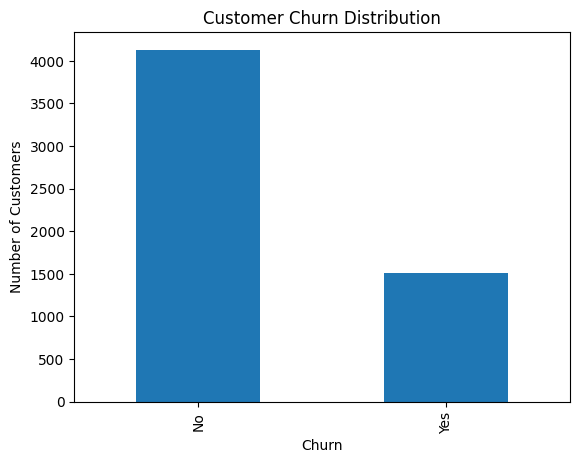

In [ ]:
#To visualize the number of customers who have churned and those who have not churned using a bar chart.
training_df['Churn'].value_counts().plot( kind='bar')
plt.title('Customer Churn Distribution')
plt.xlabel('Churn')
plt.ylabel('Number of Customers')
plt.show()

In [ ]:
# Selects all numerical columns from the training dataset.
num_cols = training_df.select_dtypes(include='number').columns

print(num_cols)

Index(['SeniorCitizen', 'tenure', 'MonthlyCharges'], dtype='object')


In [ ]:
# Generates descriptive statistical summaries (count, mean, standard deviation, minimum, maximum and quartiles) for numerical columns.
training_df[num_cols].describe()

,SeniorCitizen,tenure,MonthlyCharges
count,5634.000000,5634.000000,5240.000000
mean,0.159744,32.606851,65.102052
std,0.366401,24.614976,30.056443
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,36.800000
50%,0.000000,29.000000,70.650000
75%,0.000000,56.000000,90.050000
max,1.000000,72.000000,118.750000


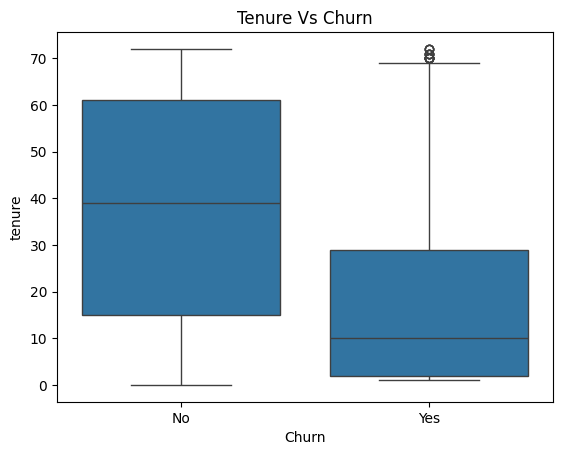

In [ ]:
#understanding the relationship b/w tenure and churn
import seaborn as sns
import matplotlib.pyplot as plt

# Use 'Churn' if it exists, otherwise use 'Churn_Yes'
churn_col = 'Churn' if 'Churn' in training_df.columns else 'Churn_Yes'

sns.boxplot(x=churn_col, y='tenure', data=training_df)
plt.title('Tenure Vs Churn')
plt.show()

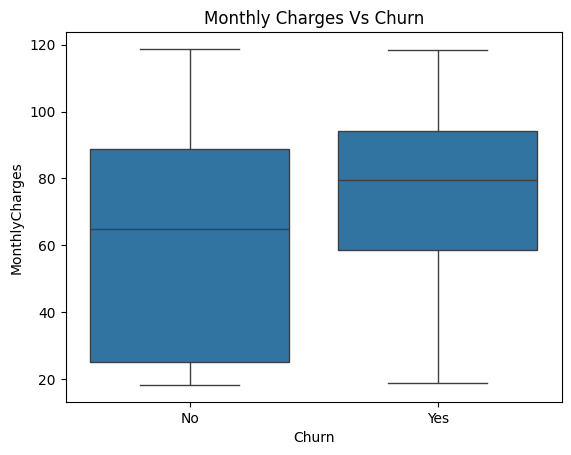

In [ ]:
#Compare monthly charges with churn
# Use 'Churn' if it exists in training_df, otherwise use 'Churn_Yes'
churn_col = 'Churn' if 'Churn' in training_df.columns else 'Churn_Yes'

sns.boxplot(x=churn_col, y='MonthlyCharges', data=training_df)
plt.title('Monthly Charges Vs Churn')
plt.show()

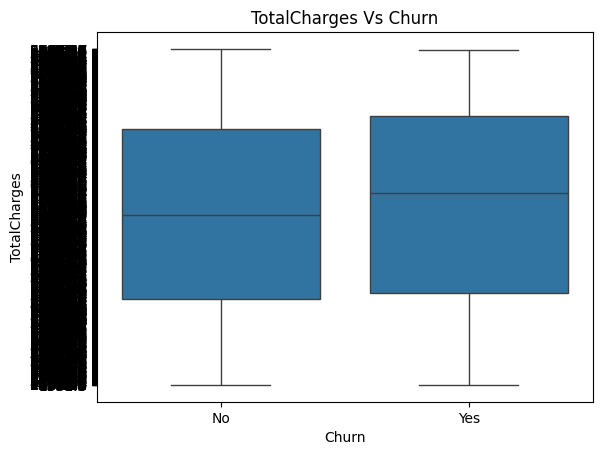

In [ ]:
# Identifies the target column (Churn or Churn_Yes) and creates a boxplot
# to compare the distribution of TotalCharges between churned and non-churned customers.
# Adds a title and displays the plot.
churn_col = 'Churn' if 'Churn' in training_df.columns else 'Churn_Yes'

sns.boxplot(x=churn_col, y='TotalCharges', data=training_df)

plt.title('TotalCharges Vs Churn')
plt.show()

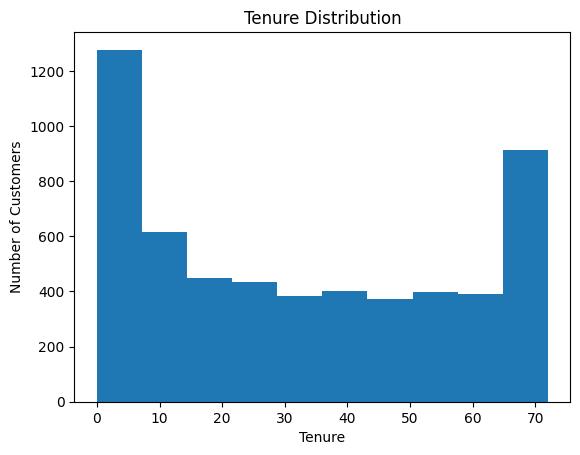

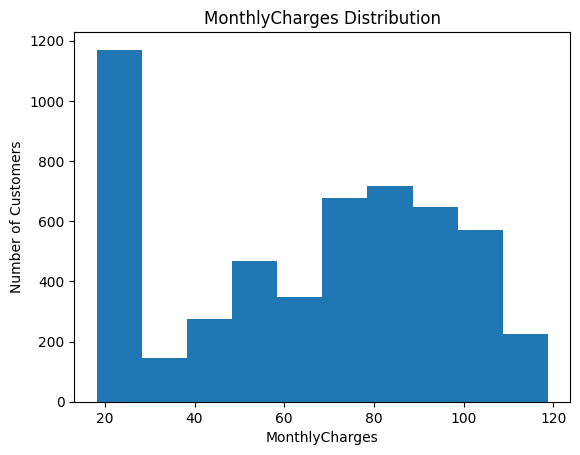

In [ ]:

# Creates a histogram to visualize the distribution of customer tenure.
# Adds title and labels to the X-axis and Y-axis, then displays the plot.

# Creates a histogram to visualize the distribution of monthly charges.
# Adds title and labels to the X-axis and Y-axis
plt.hist(training_df['tenure'])
plt.title('Tenure Distribution')
plt.xlabel('Tenure')
plt.ylabel('Number of Customers')
plt.show()

plt.hist(training_df['MonthlyCharges'])
plt.title('MonthlyCharges Distribution')
plt.xlabel('MonthlyCharges')
plt.ylabel('Number of Customers')
plt.show()

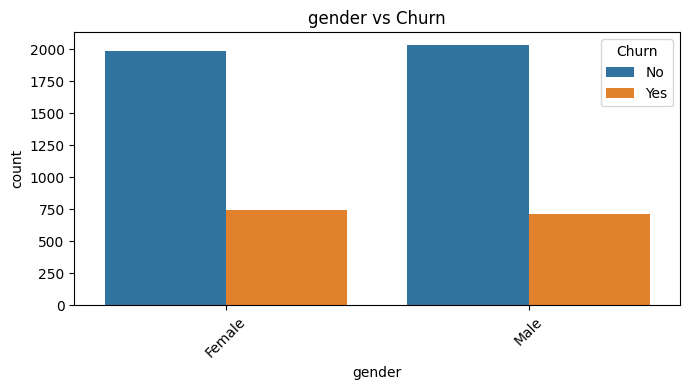

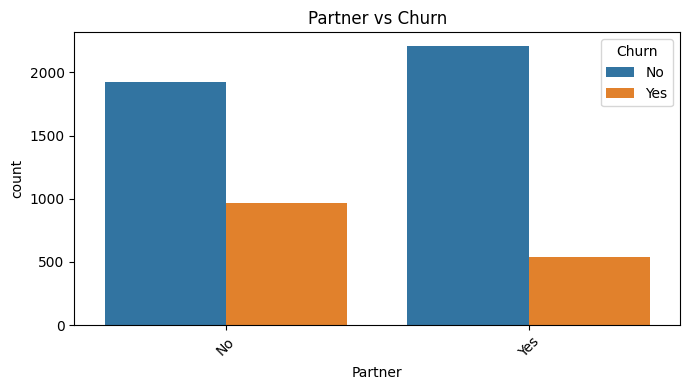

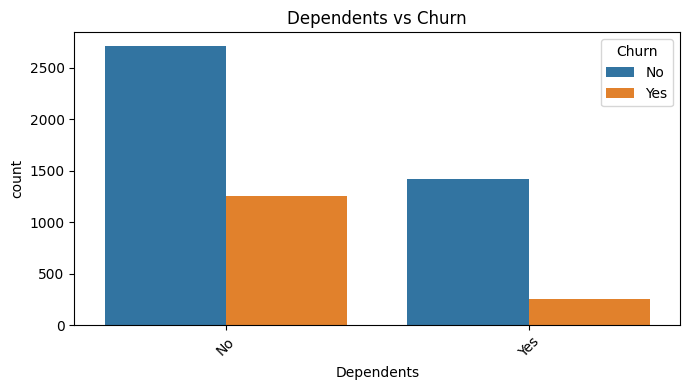

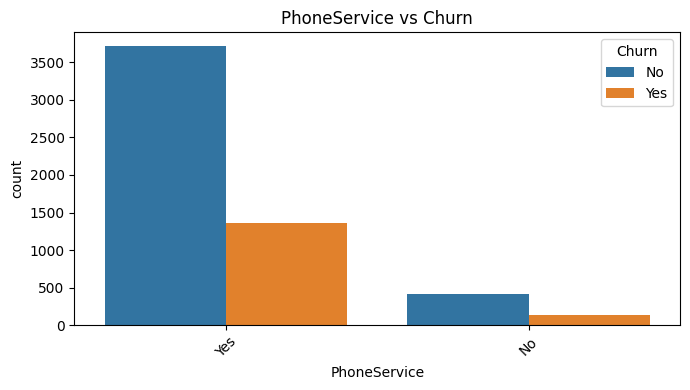

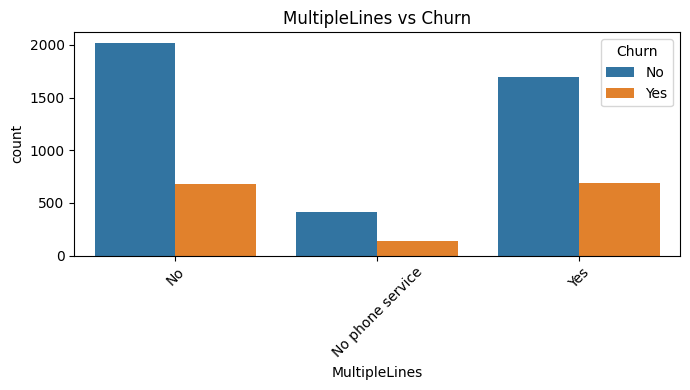

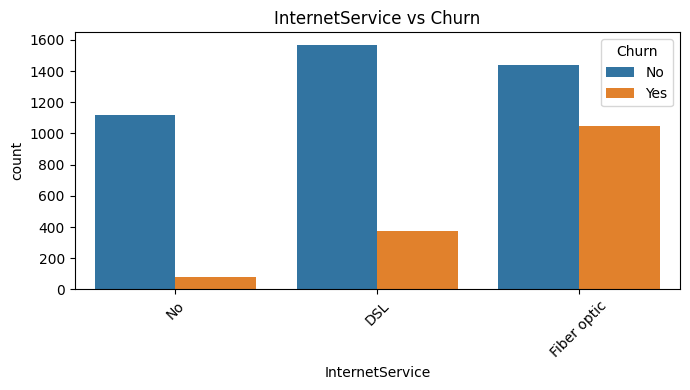

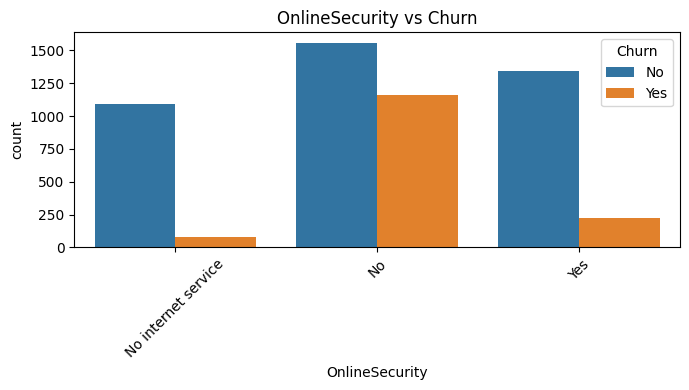

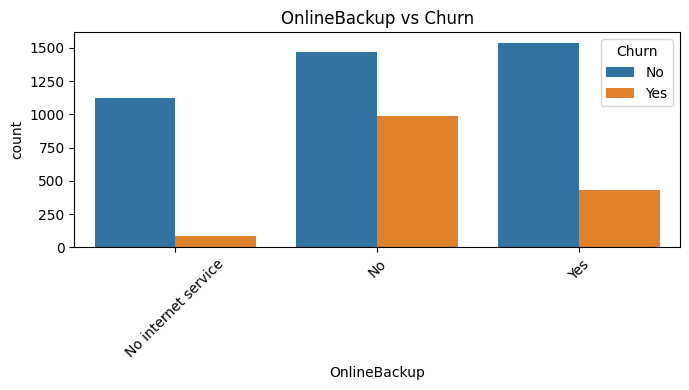

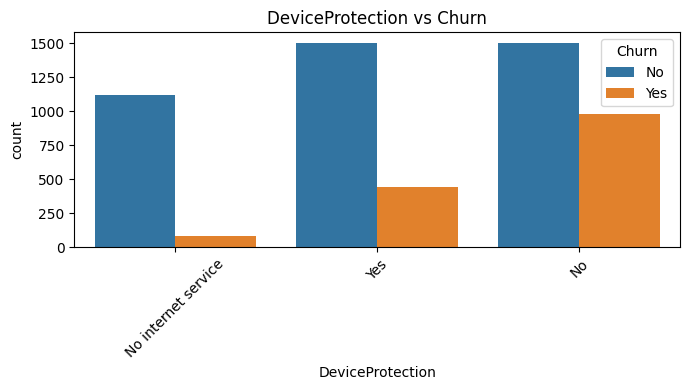

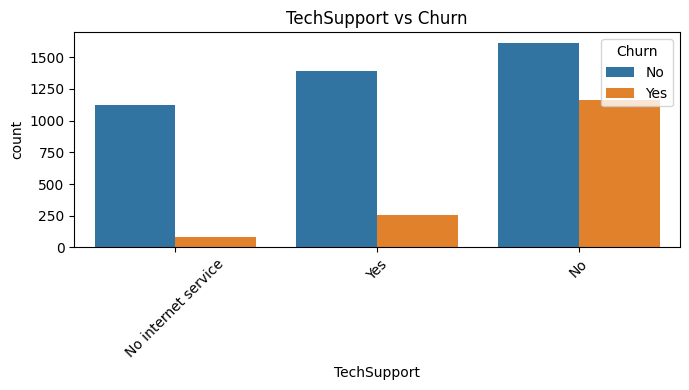

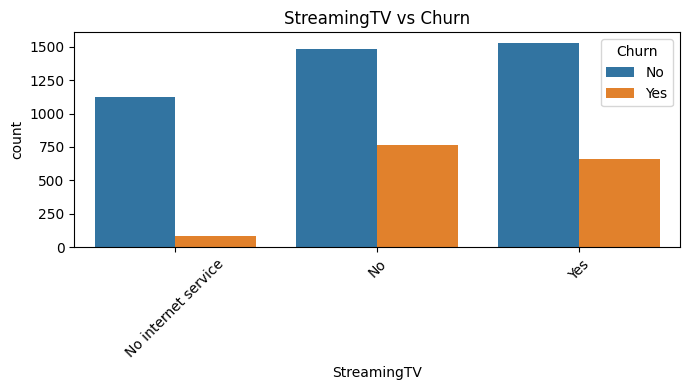

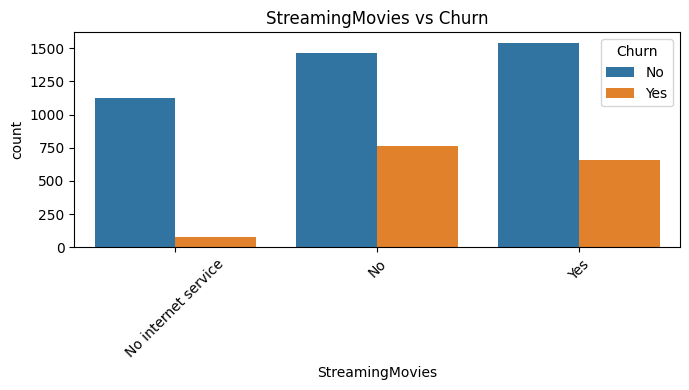

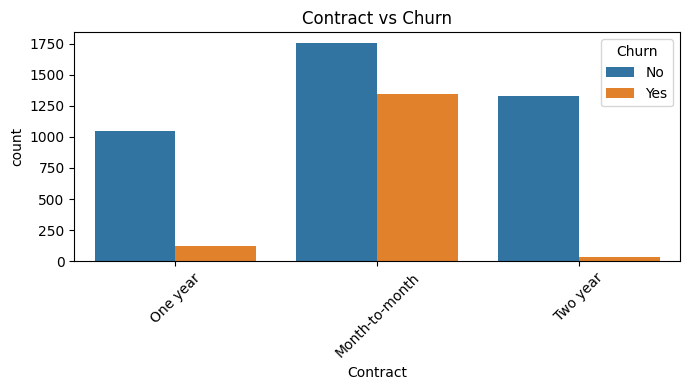

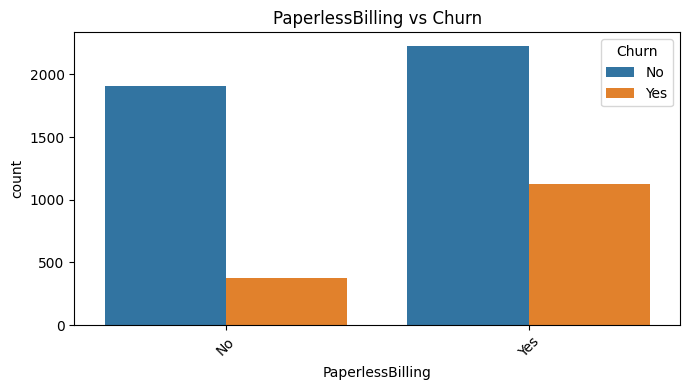

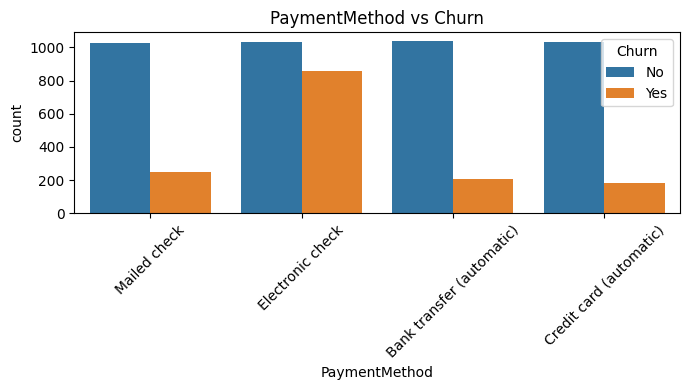

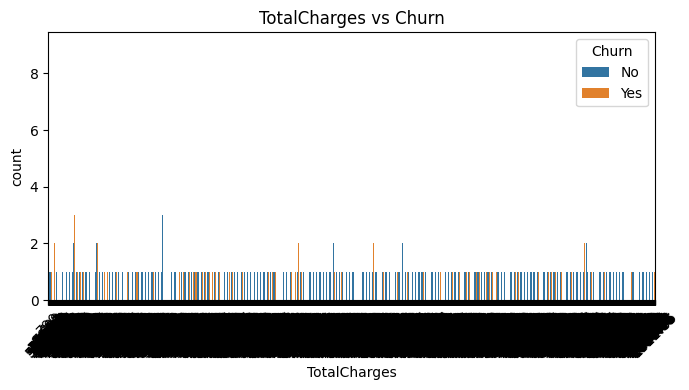

In [ ]:
# Compare all the categorical features with churn using loop.
# We read a fresh copy of training_df to ensure we have the original categorical columns and Churn column

categorical_cols = [
    col for col in training_df.select_dtypes(include='object').columns
    if col not in ['customerID', 'Churn']
]

for col in categorical_cols:
    plt.figure(figsize=(7, 4))
    sb.countplot(data=training_df, x=col, hue='Churn')
    plt.title(f'{col} vs Churn')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

In [ ]:
# Selects the numerical columns required for correlation analysis.
# Creates a copy of the selected columns to avoid modifying the original dataset.
# Adds the TotalCharges column using the converted numerical values.
# Calculates the correlation matrix to identify relationships between numerical variables.
correlation_data = training_df[
    ['SeniorCitizen', 'tenure', 'MonthlyCharges']
].copy()

correlation_data['TotalCharges'] = numeric

correlation_matrix = correlation_data.corr()

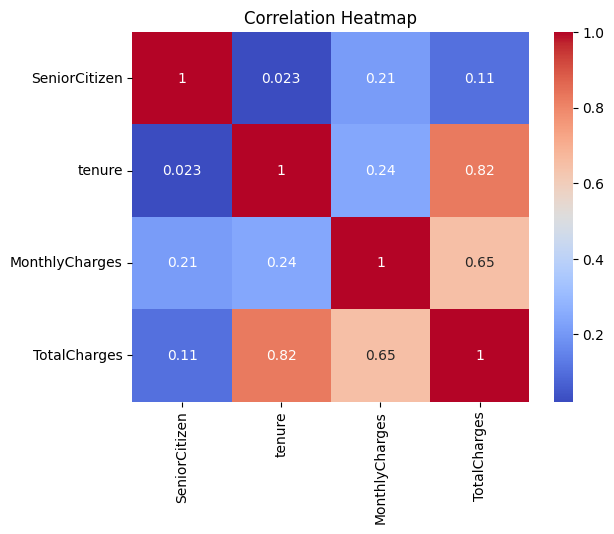

In [ ]:
# Creates a heatmap to visualize the correlation between numerical variables.
# annot=True displays the correlation values inside each cell.
# cmap='coolwarm' applies different colours to represent positive and negative correlations.
# Adds a title and displays the heatmap.
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm')

plt.title('Correlation Heatmap')
plt.show()

2. Data Preprocessing:

In [ ]:
#Handling the missing values of MonthlyCharges and filling it with median
training_df['MonthlyCharges']= training_df['MonthlyCharges'].fillna(
    training_df['MonthlyCharges'].median()
)

In [ ]:
# Fills missing values in the gender column using the mode (most frequently occurring value).
# mode()[0] selects the most frequent gender value.
training_df['gender']= training_df['gender'].fillna(
    training_df['gender'].mode()[0]
)


In [ ]:
# Fills missing values in the OnlineSecurity column using the mode (most frequently occurring value).
# mode()[0] selects the most common category.
training_df['OnlineSecurity'] = training_df['OnlineSecurity'].fillna(
    training_df['OnlineSecurity'].mode()[0]
)

In [ ]:
# Converts the TotalCharges column from object (string) datatype to numeric datatype.
# errors='coerce' converts invalid or non-numeric values into NaN (missing values).
training_df['TotalCharges'] = pd.to_numeric(training_df['TotalCharges'], errors='coerce')

In [ ]:
# Fills missing values in the TotalCharges column using the median value.
# The median is used to handle missing numerical values.
training_df['TotalCharges']= training_df['TotalCharges'].fillna(
    training_df['TotalCharges'].median()
    )

In [ ]:
training_df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


**Categorical Encoding**

Label Encoding: Assigns numerical values to categories.



One-Hot Encoding: Creates separate binary columns for each category.

In [ ]:
# Identify categorical columns.
categorical_cols = training_df.select_dtypes(include='object').columns.tolist()



# Exclude
# customerID: Unique identifier; it doesn't provide useful predictive information.
# Churn: This is our target variable, which we want to predict. It must not be included as an input feature.

categorical_cols.remove('customerID')
categorical_cols.remove('Churn')

print(categorical_cols)

['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


**One-Hot Encoding**

use get_dummies() to understand how One-Hot Encoding works

Converts each categorical feature into separate binary columns.

1 means the category is present.

0 means the category is absent.

Keeps numerical columns unchanged.

In [ ]:
train_encoded = pd.get_dummies(
    training_df,
    columns=categorical_cols,
    dtype=int
)

print(train_encoded.shape)
print("\  n","\n")
print(train_encoded.head())

(5634, 47)
\  n 

   customerID  SeniorCitizen  tenure  MonthlyCharges  TotalCharges Churn  \
0  9509-MPYOD              0      35           20.75        700.45    No   
1  7746-AWNQW              0      28           35.75        961.40    No   
2  2208-UGTGR              0      56           98.60       5581.05    No   
3  4884-LEVMQ              0      39           20.45        790.00    No   
4  6682-VCIXC              0      43           51.25       2151.60    No   

   gender_Female  gender_Male  Partner_No  Partner_Yes  ...  \
0              1            0           1            0  ...   
1              1            0           1            0  ...   
2              0            1           1            0  ...   
3              0            1           0            1  ...   
4              1            0           0            1  ...   

   StreamingMovies_Yes  Contract_Month-to-month  Contract_One year  \
0                    0                        0                  1   
1     

<>:8: SyntaxWarning: invalid escape sequence '\ '
<>:8: SyntaxWarning: invalid escape sequence '\ '
/tmp/ipykernel_869/3661710507.py:8: SyntaxWarning: invalid escape sequence '\ '
  print("\  n","\n")


In [ ]:
# scale the numerical columns in a separate DataFrame.
numerical_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

scaler = StandardScaler()

train_scaled = training_df.copy()

# Ensure all columns are numeric, converting errors (like empty spaces ' ') to NaN
for col in numerical_cols:
    train_scaled[col] = pd.to_numeric(train_scaled[col], errors='coerce')
    # Fill any NaN values with the median of that column
    train_scaled[col] = train_scaled[col].fillna(train_scaled[col].median())

train_scaled[numerical_cols] = scaler.fit_transform(
    train_scaled[numerical_cols]
)

train_scaled[numerical_cols].head()

,tenure,MonthlyCharges,TotalCharges
0,0.097232,-1.541793,-0.693923
1,-0.187173,-1.024876,-0.576171
2,0.950447,1.141008,1.508417
3,0.259749,-1.552131,-0.653514
4,0.422266,-0.490728,-0.039101


In [ ]:
# Outlier Handling
# IQR
col = ['tenure','MonthlyCharges', 'TotalCharges']

for col in numerical_cols:

 Q1 = training_df[col].quantile(0.25)
 Q3 = training_df[col].quantile(0.75)

 IQR = Q3 - Q1
 lower = Q1 - 1.5 * IQR
 upper = Q3 + 1.5 * IQR

 outliers = training_df[
        (training_df[col] < lower) | (training_df[col] > upper)
    ]

 print(f'{col}: {len(outliers)} outliers')

tenure: 0 outliers
MonthlyCharges: 0 outliers
TotalCharges: 0 outliers


In [ ]:
Q1 = training_df['TotalCharges'].quantile(0.25)
Q3 = training_df['TotalCharges'].quantile(0.75)
IQR = Q3 - Q1

upper = Q3 + 1.5 * IQR
lower = Q1 - 1.5 * IQR

outliers = training_df[training_df['TotalCharges'] > upper]
print(f'TotalCharges: {len(outliers)} outliers')

TotalCharges: 0 outliers


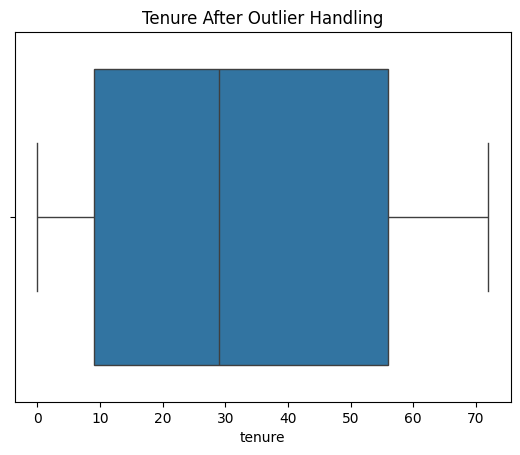

In [ ]:
sns.boxplot(x=training_df['tenure'])
plt.title('Tenure After Outlier Handling')
plt.show()

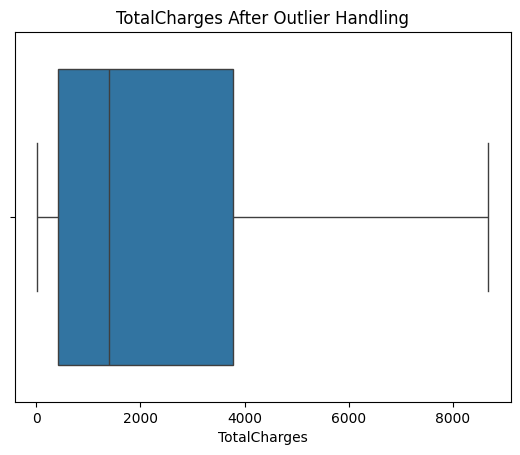

In [ ]:
sns.boxplot(x=training_df['TotalCharges'])
plt.title('TotalCharges After Outlier Handling')
plt.show()

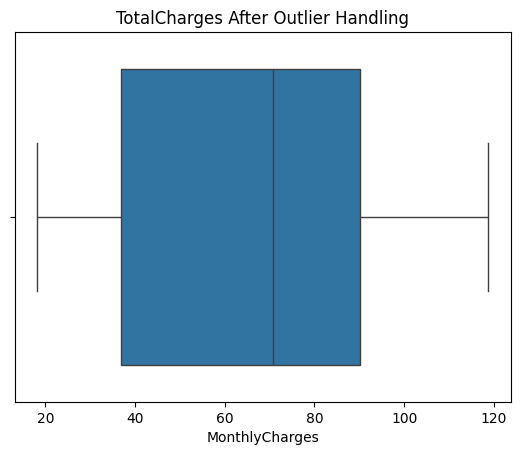

In [ ]:
sns.boxplot(x=training_df['MonthlyCharges'])
plt.title('TotalCharges After Outlier Handling')
plt.show()

3. Feature Engineering:

In [ ]:
train_scaled['CLV'] = training_df['tenure'] * training_df['MonthlyCharges']

In [ ]:
test_scaled = testing_df.copy()
test_scaled['CLV'] = testing_df['tenure'] * testing_df['MonthlyCharges']
test_scaled[['tenure', 'MonthlyCharges', 'CLV']].head()

,tenure,MonthlyCharges,CLV
0,40,81.20,3248.0
1,12,78.85,946.2
2,43,100.00,4300.0
3,72,118.20,8510.4
4,10,36.25,362.5


In [ ]:
training_df['Contract'].unique()

array(['One year', 'Month-to-month', 'Two year'], dtype=object)

In [ ]:
# Create a new feature by combining Tenure and Contract
train_scaled['Tenure_Contract'] = (
    training_df['tenure'].astype(str) + '_' + training_df['Contract']
)

# Display the newly created feature
train_scaled[['Tenure_Contract']].head()

,Tenure_Contract
0,35_One year
1,28_Month-to-month
2,56_Month-to-month
3,39_Two year
4,43_One year


In [ ]:
# Create the same feature in the testing dataset
test_scaled['Tenure_Contract'] = (
    testing_df['tenure'].astype(str) + '_' + testing_df['Contract']
)

# Display the newly created feature
test_scaled[['Tenure_Contract']].head()

,Tenure_Contract
0,40_Month-to-month
1,12_One year
2,43_One year
3,72_Two year
4,10_Month-to-month


In [ ]:
# Define tenure ranges
bins = [0, 12, 24, 48, 72]

# Create tenure groups in the training dataset
training_df['TenureGroup'] = pd.cut(
    training_df['tenure'],
    bins=bins,
    labels=['0-12', '13-24', '25-48', '49-72'],
    include_lowest=True
)

# Display the tenure groups
training_df[['tenure', 'TenureGroup']].head()

,tenure,TenureGroup
0,35,25-48
1,28,25-48
2,56,49-72
3,39,25-48
4,43,25-48


In [ ]:
# Define the same tenure ranges used in training
bins = [0, 12, 24, 48, 72]

# Create tenure groups in the testing dataset
testing_df['TenureGroup'] = pd.cut(
    testing_df['tenure'],
    bins=bins,
    labels=['0-12', '13-24', '25-48', '49-72'],
    include_lowest=True
)

# Display the tenure groups
testing_df[['tenure', 'TenureGroup']].head()

,tenure,TenureGroup
0,40,25-48
1,12,0-12
2,43,25-48
3,72,49-72
4,10,0-12


In [ ]:
# Combine TenureGroup and Contract into one new feature
train_scaled['Tenure_Contract_Group'] = (
    training_df['TenureGroup'].astype(str) + '_' +
    training_df['Contract']
)

# Display the new interaction feature
train_scaled[['Tenure_Contract_Group']].head()

,Tenure_Contract_Group
0,25-48_One year
1,25-48_Month-to-month
2,49-72_Month-to-month
3,25-48_Two year
4,25-48_One year


In [ ]:
# Create the same interaction feature in the testing dataset
test_scaled['Tenure_Contract_Group'] = (
    testing_df['TenureGroup'].astype(str) + '_' +
    testing_df['Contract']
)

# Display the new interaction feature
test_scaled[['Tenure_Contract_Group']].head()

,Tenure_Contract_Group
0,25-48_Month-to-month
1,0-12_One year
2,25-48_One year
3,49-72_Two year
4,0-12_Month-to-month


In [ ]:
# Display information about the processed training dataset
train_scaled.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5634 entries, 0 to 5633
Data columns (total 24 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   customerID             5634 non-null   object 
 1   gender                 5465 non-null   object 
 2   SeniorCitizen          5634 non-null   int64  
 3   Partner                5634 non-null   object 
 4   Dependents             5634 non-null   object 
 5   tenure                 5634 non-null   float64
 6   PhoneService           5634 non-null   object 
 7   MultipleLines          5634 non-null   object 
 8   InternetService        5634 non-null   object 
 9   OnlineSecurity         5465 non-null   object 
 10  OnlineBackup           5634 non-null   object 
 11  DeviceProtection       5634 non-null   object 
 12  TechSupport            5634 non-null   object 
 13  StreamingTV            5634 non-null   object 
 14  StreamingMovies        5634 non-null   object 
 15  Cont

In [ ]:
# Display the first five rows of the dataset
train_scaled.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,CLV,Tenure_Contract,Tenure_Contract_Group
0,9509-MPYOD,Female,0,No,No,0.097232,Yes,No,No,No internet service,...,No internet service,One year,No,Mailed check,-1.541793,-0.693923,No,726.25,35_One year,25-48_One year
1,7746-AWNQW,Female,0,No,No,-0.187173,No,No phone service,DSL,No,...,No,Month-to-month,Yes,Mailed check,-1.024876,-0.576171,No,1001.00,28_Month-to-month,25-48_Month-to-month
2,2208-UGTGR,Male,0,No,No,0.950447,Yes,Yes,Fiber optic,No,...,Yes,Month-to-month,No,Electronic check,1.141008,1.508417,No,5521.60,56_Month-to-month,49-72_Month-to-month
3,4884-LEVMQ,Male,0,Yes,No,0.259749,Yes,No,No,No internet service,...,No internet service,Two year,Yes,Bank transfer (automatic),-1.552131,-0.653514,No,797.55,39_Two year,25-48_Two year
4,6682-VCIXC,Female,0,Yes,Yes,0.422266,No,No phone service,DSL,NaN,...,No,One year,Yes,Bank transfer (automatic),-0.490728,-0.039101,No,2203.75,43_One year,25-48_One year


In [ ]:
# Separate input features by removing customerID and Churn
X = train_scaled.drop(['customerID', 'Churn'], axis=1)

# Store Churn as the target variable
y = train_scaled['Churn']

In [ ]:
# Convert categorical features into numerical dummy variables
X = pd.get_dummies(X, drop_first=True)

# Display the encoded features
X.head()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,CLV,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,...,Tenure_Contract_Group_0-12_Two year,Tenure_Contract_Group_13-24_Month-to-month,Tenure_Contract_Group_13-24_One year,Tenure_Contract_Group_13-24_Two year,Tenure_Contract_Group_25-48_Month-to-month,Tenure_Contract_Group_25-48_One year,Tenure_Contract_Group_25-48_Two year,Tenure_Contract_Group_49-72_Month-to-month,Tenure_Contract_Group_49-72_One year,Tenure_Contract_Group_49-72_Two year
0,0,0.097232,-1.541793,-0.693923,726.25,False,False,False,True,False,...,False,False,False,False,False,True,False,False,False,False
1,0,-0.187173,-1.024876,-0.576171,1001.00,False,False,False,False,True,...,False,False,False,False,True,False,False,False,False,False
2,0,0.950447,1.141008,1.508417,5521.60,True,False,False,True,False,...,False,False,False,False,False,False,False,True,False,False
3,0,0.259749,-1.552131,-0.653514,797.55,True,True,False,True,False,...,False,False,False,False,False,False,True,False,False,False
4,0,0.422266,-0.490728,-0.039101,2203.75,False,True,True,False,True,...,False,False,False,False,False,True,False,False,False,False


In [ ]:
from sklearn.ensemble import RandomForestClassifier

# Create the Random Forest model
rf = RandomForestClassifier(random_state=42)

# Train the model using the input features and target
rf.fit(X, y)

RandomForestClassifier(random_state=42)

In [ ]:
# Get the importance score of each feature
feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf.feature_importances_
})

# Sort features from most important to least important
feature_importance = feature_importance.sort_values(
    by='Importance', ascending=False
)

# Display the top 15 important features
feature_importance.head(15)

,Feature,Importance
4,CLV,0.115938
3,TotalCharges,0.111228
2,MonthlyCharges,0.100508
1,tenure,0.079770
11,InternetService_Fiber optic,0.033068
29,PaymentMethod_Electronic check,0.032295
14,OnlineSecurity_Yes,0.022501
26,Contract_Two year,0.021750
27,PaperlessBilling_Yes,0.021724
5,gender_Male,0.021605


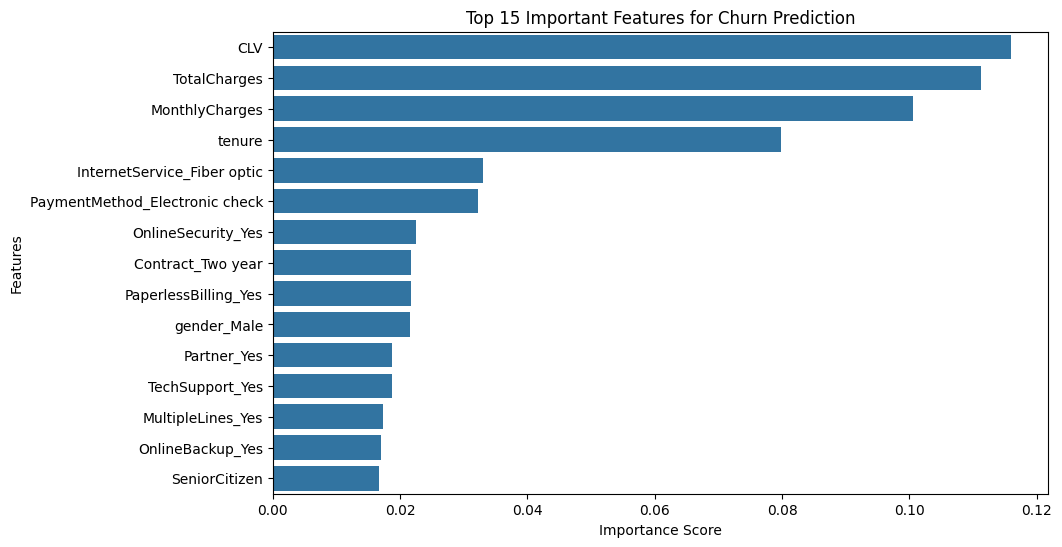

In [ ]:
# Select the top 15 most important features
top_features = feature_importance.head(15)

# Create a bar plot to visualize feature importance
plt.figure(figsize=(10, 6))

sns.barplot(
    x='Importance',
    y='Feature',
    data=top_features
)

# Add chart title and labels
plt.title('Top 15 Important Features for Churn Prediction')
plt.xlabel('Importance Score')
plt.ylabel('Features')

plt.show()

In [ ]:
# Select the input features by removing customerID and Churn
X = train_scaled.drop(['customerID', 'Churn'], axis=1)

# Select Churn as the target variable
y = train_scaled['Churn']

# Convert categorical input features into numerical columns
X = pd.get_dummies(X, drop_first=True)

# Display the shape of the input features
print("Input features:", X.shape)

# Display the target variable
print("Target variable:", y.shape)

Input features: (5634, 256)
Target variable: (5634,)


4.. Model Development:

In [ ]:
from sklearn.model_selection import train_test_split

# Split the dataset into training and validation sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Display the size of each dataset
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (4507, 256)
X_test: (1127, 256)
y_train: (4507,)
y_test: (1127,)


In [ ]:
# Show columns that have missing values
X_train.isnull().sum()[X_train.isnull().sum() > 0]

,0
CLV,327


In [ ]:
# Count all missing values in the training data
print("Missing values:", X_train.isnull().sum().sum())

Missing values: 327


In [ ]:
# Count missing values in each column
missing_values = X_train.isnull().sum()

# Display only columns containing missing values
print(missing_values[missing_values > 0])

CLV    327
dtype: int64


In [ ]:
# Check missing values in the columns used to calculate CLV
print("Tenure missing:", training_df['tenure'].isnull().sum())
print("MonthlyCharges missing:", training_df['MonthlyCharges'].isnull().sum())

# Check missing values in the newly created CLV feature
print("CLV missing:", train_scaled['CLV'].isnull().sum())

Tenure missing: 0
MonthlyCharges missing: 394
CLV missing: 394


In [ ]:
# Fill missing CLV values using the training data median
clv_median = X_train['CLV'].median()

X_train['CLV'] = X_train['CLV'].fillna(clv_median)

# Use the same median for testing data
X_test['CLV'] = X_test['CLV'].fillna(clv_median)

# Verify missing values
print("Training missing:", X_train['CLV'].isnull().sum())
print("Testing missing:", X_test['CLV'].isnull().sum())

Training missing: 0
Testing missing: 0


In [ ]:
# Import Logistic Regression
from sklearn.linear_model import LogisticRegression

# Create the Logistic Regression model
lr_model = LogisticRegression(max_iter=1000)

# Train the model using training data
lr_model.fit(X_train, y_train)

# Predict churn using testing data
y_pred_lr = lr_model.predict(X_test)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [ ]:
# Create Logistic Regression with more iterations
lr_model = LogisticRegression(max_iter=3000)

# Train the model
lr_model.fit(X_train, y_train)

# Predict churn
y_pred_lr = lr_model.predict(X_test)

In [ ]:
# Import accuracy score
from sklearn.metrics import accuracy_score

# Calculate Logistic Regression accuracy
lr_accuracy = accuracy_score(y_test, y_pred_lr)

# Display accuracy
print("Logistic Regression Accuracy:", lr_accuracy)

Logistic Regression Accuracy: 0.8012422360248447


In [ ]:
# Import evaluation metrics
from sklearn.metrics import precision_score, recall_score, f1_score

# Calculate precision
lr_precision = precision_score(y_test, y_pred_lr, pos_label='Yes')

# Calculate recall
lr_recall = recall_score(y_test, y_pred_lr, pos_label='Yes')

# Calculate F1-score
lr_f1 = f1_score(y_test, y_pred_lr, pos_label='Yes')

# Display all metrics
print("Precision:", lr_precision)
print("Recall:", lr_recall)
print("F1 Score:", lr_f1)

Precision: 0.6498054474708171
Recall: 0.5548172757475083
F1 Score: 0.5985663082437276


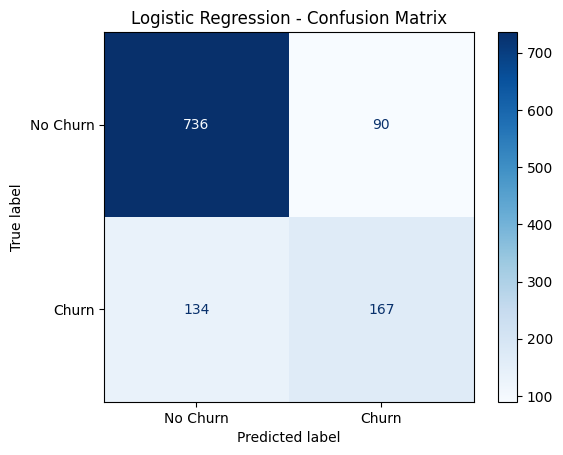

In [ ]:
# Import confusion matrix
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Calculate confusion matrix
cm = confusion_matrix(y_test, y_pred_lr, labels=['No', 'Yes'])

# Display confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['No Churn', 'Churn']
)

disp.plot(cmap='Blues')
plt.title('Logistic Regression - Confusion Matrix')
plt.show()

In [ ]:
# Import Decision Tree Classifier
from sklearn.tree import DecisionTreeClassifier

# Create the Decision Tree model
dt_model = DecisionTreeClassifier(random_state=42)

# Train the model
dt_model.fit(X_train, y_train)

# Predict churn
y_pred_dt = dt_model.predict(X_test)

In [ ]:
# Import accuracy score
from sklearn.metrics import accuracy_score

# Calculate accuracy
dt_accuracy = accuracy_score(y_test, y_pred_dt)

# Display accuracy
print("Decision Tree Accuracy:", dt_accuracy)

Decision Tree Accuracy: 0.7240461401952085


In [ ]:
# Calculate precision
dt_precision = precision_score(y_test, y_pred_dt, pos_label='Yes')

# Calculate recall
dt_recall = recall_score(y_test, y_pred_dt, pos_label='Yes')

# Calculate F1-score
dt_f1 = f1_score(y_test, y_pred_dt, pos_label='Yes')

# Display evaluation metrics
print("Precision:", dt_precision)
print("Recall:", dt_recall)
print("F1 Score:", dt_f1)

Precision: 0.4837662337662338
Recall: 0.4950166112956811
F1 Score: 0.48932676518883417


In [ ]:
# Import Random Forest Classifier
from sklearn.ensemble import RandomForestClassifier

# Create the Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train the model
rf_model.fit(X_train, y_train)

# Predict churn
y_pred_rf = rf_model.predict(X_test)

In [ ]:
# Calculate Random Forest accuracy
rf_accuracy = accuracy_score(y_test, y_pred_rf)

# Display accuracy
print("Random Forest Accuracy:", rf_accuracy)


Random Forest Accuracy: 0.8065661047027507


In [ ]:
# Calculate precision
rf_precision = precision_score(y_test, y_pred_rf, pos_label='Yes')

# Calculate recall
rf_recall = recall_score(y_test, y_pred_rf, pos_label='Yes')

# Calculate F1-score
rf_f1 = f1_score(y_test, y_pred_rf, pos_label='Yes')

# Display evaluation metrics
print("Precision:", rf_precision)
print("Recall:", rf_recall)
print("F1 Score:", rf_f1)

Precision: 0.6721991701244814
Recall: 0.5382059800664452
F1 Score: 0.5977859778597786


### Model Comparison and Selection

Three machine learning algorithms were implemented and evaluated for customer churn prediction: Logistic Regression, Decision Tree Classifier, and Random Forest Classifier.

Based on the evaluation results:

- **Logistic Regression** achieved an accuracy of 80.12% and the highest recall (55.48%) and F1-score (59.86%).
- **Decision Tree** achieved an accuracy of 72.40%, showing the lowest performance among the three models.
- **Random Forest** achieved the highest accuracy of 80.66% and precision of 67.22%.

**Conclusion:**

Random Forest is selected as the preliminary best-performing model because it achieved the highest accuracy and precision. However, Logistic Regression showed slightly better recall and F1-score. Therefore, both models are worth considering for churn prediction.

Further hyperparameter tuning will be performed to improve model performance.

5. Model Fine-Tuning:

In [ ]:
# Import GridSearchCV for hyperparameter tuning
from sklearn.model_selection import GridSearchCV

In [ ]:
# Define hyperparameters to test
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5]
}

In [ ]:
# Create GridSearchCV using the Random Forest model
grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1,
    verbose=1
)

In [ ]:
# Display the best hyperparameters
print("Best Parameters:", grid_search.best_params_)

# Display the best cross-validation F1-score
print("Best CV F1 Score:", grid_search.best_score_)

Best Parameters: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 100}
Best CV F1 Score: nan


In [ ]:
# Import make_scorer
from sklearn.metrics import make_scorer, f1_score

# Set 'Yes' as the positive class
f1_scorer = make_scorer(f1_score, pos_label='Yes')

In [ ]:
# Create GridSearchCV with the corrected F1 scorer
grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring=f1_scorer,
    n_jobs=-1,
    verbose=1
)

In [414]:
# Fit GridSearchCV using training data
grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 12 candidates, totalling 60 fits


GridSearchCV(cv=5, estimator=RandomForestClassifier(random_state=42), n_jobs=-1,
             param_grid={'max_depth': [None, 10, 20],
                         'min_samples_split': [2, 5],
                         'n_estimators': [100, 200]},
             scoring=make_scorer(f1_score, response_method='predict', pos_label=Yes),
             verbose=1)

In [415]:
# Display the best hyperparameters
print("Best Parameters:", grid_search.best_params_)

# Display the best cross-validation F1-score
print("Best CV F1 Score:", grid_search.best_score_)

Best Parameters: {'max_depth': 20, 'min_samples_split': 5, 'n_estimators': 100}
Best CV F1 Score: 0.5601590551778711


In [416]:
# Get the best tuned Random Forest model
best_rf_model = grid_search.best_estimator_

# Predict churn using test data
y_pred_tuned = best_rf_model.predict(X_test)

# Import evaluation metrics
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Calculate evaluation metrics
print("Accuracy:", accuracy_score(y_test, y_pred_tuned))
print("Precision:", precision_score(y_test, y_pred_tuned, pos_label='Yes'))
print("Recall:", recall_score(y_test, y_pred_tuned, pos_label='Yes'))
print("F1 Score:", f1_score(y_test, y_pred_tuned, pos_label='Yes'))

Accuracy: 0.8047914818101154
Precision: 0.6639676113360324
Recall: 0.5448504983388704
F1 Score: 0.5985401459854015


# Conclusion and Business Recommendations

## Conclusion

The Customer Churn Prediction project aimed to identify customers who are likely to discontinue their telecommunications services using machine learning techniques.

Exploratory Data Analysis helped identify patterns and relationships between customer characteristics and churn. Data preprocessing was performed to handle missing values, encode categorical variables, scale numerical features, and address outliers.

Feature engineering was used to create additional features such as Customer Lifetime Value (CLV) and tenure-related interaction features.

Three machine learning algorithms were implemented:
- Logistic Regression
- Decision Tree Classifier
- Random Forest Classifier

Among the three models, Random Forest achieved the highest initial accuracy of 80.66%. Hyperparameter tuning using GridSearchCV produced a tuned Random Forest model with an accuracy of 80.48% and an F1-score of 59.85%.

The results show that machine learning can help predict customer churn and support better customer retention strategies.

## Business Recommendations

Based on the analysis, the following recommendations can help a telecommunications company reduce customer churn:

1. **Identify high-risk customers:** Use the churn prediction model to identify customers who are more likely to leave the service.

2. **Improve customer retention:** Offer personalized discounts, loyalty rewards, and special packages to customers at risk of churning.

3. **Focus on customer support:** Improve technical support and customer service to increase customer satisfaction.

4. **Encourage long-term contracts:** Provide attractive benefits to encourage customers to choose long-term subscription plans.

5. **Monitor customer behaviour:** Regularly analyze customer tenure, monthly charges, service usage, and payment patterns to identify possible churn risks.

6. **Continuously improve the model:** Update the prediction model with new customer data and monitor its performance regularly.

## Final Outcome

This project demonstrates how data analysis and machine learning can be applied to customer churn prediction. By identifying customers at risk of leaving, telecommunications companies can take proactive steps to improve customer satisfaction, strengthen customer relationships, and reduce customer loss.